# Owner communities

Who owns what, quarter by quarter: every organization in the provider graph placed in one community with its owner, the owner's facilities' legal entities, and the physician groups it employs. `healthcare-ledger owner-communities` builds the tables from a graph built with `--ownership --compendium` ([METHODOLOGY.md](../../docs/METHODOLOGY.md) section 8f). This notebook checks them.

The method is record linkage (Fellegi and Sunter 1969) feeding correlation clustering (Leiden on the Constant Potts Model; Traag, Waltman and van Eck 2019), carried over time by evolutionary clustering (Chakrabarti, Kumar and Tomkins 2006):

* **Hard links** are taken as given. An organization in a CMS All Owners firm (2022 on) is tied to its firm; a firm, or a facility outside any firm, joins the AHRQ Compendium system holding most of its listed facilities; a Compendium physician group joins its system unless it belongs to a staffing company.
* **Soft links** are priced. NPPES keys (the authorized official, the mailing address, the practice phone, a subpart's parent organization), the chain home office on a facility's Medicare cost report (HCRIS), the owners Nursing Home Compare listed for a nursing home, and the organizations a Form 990's Schedule R relates (carried to the graph by insurers' Transparency in Coverage EIN rosters). A pair's set of shared kinds, the size and cohesion of its strongest key and a shared name word make its cell; the cell's probability of common ownership is the share of known pairs under one owner on 30 December 2022.
* **Clustering** keeps a community when its pairs are, on the whole, more likely than not to share an owner. Each quarter starts from the last; a pair together last quarter needs p > 0.4 to stay, a new pair p > 0.5 to join.

| Check | Result |
|---|---|
| Held out on the anchor quarter, soft evidence only, scored on the other half of known owners | Compendium systems: pair precision 0.91, recall 0.15 (NPPES keys alone: 0.99, 0.04). All Owners firms: 0.74, 0.77 (NPPES alone: 0.74, 0.42) |
| The same calibration four years back (July 2018, systems) and four years forward (September 2026) | 2018: 0.94, 0.13. 2026: systems 0.92, 0.18; firms 0.74, 0.33 |
| Resolution γ = 0.4, 0.5, 0.6 | firms: precision 0.68, 0.74, 0.79 and recall 0.81, 0.77, 0.67; systems within a point of 0.91 and 0.15 |
| Hand audit 1, 123 labelled pairs sharing an NPPES key | 82 of 98 same-owner pairs together (95% CI 0.75 to 0.90); 13 of 25 different-owner pairs merged (0.34 to 0.70) |
| Hand audit 2, 146 labelled pairs stratified by kind, type and era | 79 of 133 same-owner pairs together (facilities 46 of 81, groups 33 of 52); 2 of 13 different-owner pairs merged. The misses are chains whose facilities All Owners places in separate firms (an operator is not an owner) |
| CMS changes of ownership, 2016 to 2026 | Before a transfer, buyer and seller are apart in 49% of hospital and 95% of nursing-home transfers; after it, the facility sits with the buyer in 82% and 71% |
| Churn per quarter with no input change, 43 quarters | 0.4 to 1.3%, mean 0.7%; 1.3 to 2.3% at a new Compendium year; 7,775 of 143,811 moves return to the community left |
| Physicians in groups in a community of two or more | 68% in 2016, 74% in 2026 (52% under hard links alone); Kaiser Permanente keeps one id from 17,300 to 24,700 physicians |
| The Compendium's headline, same physicians and years | Compendium system share 54.3% (2016) to 62.7% (2022); community holding a Compendium system 55.8% to 64.3%; community holding a hospital 55.3% to 62.0%; over every physician in the graph, 45.2% to 53.1% |

The cell below loads the graph's tables. Set `LEDGER_GRAPH` to the graph directory, `LEDGER_WAREHOUSE` to the warehouse and `LEDGER_TIC` to the Transparency in Coverage heads (the held-out cells rebuild quarters' evidence from them).

In [1]:
import csv, json, math, os, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from healthcare_ledger.derived import owner_communities as oc

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

GRAPH = Path(os.environ.get("LEDGER_GRAPH", "../../graph")).resolve()
WAREHOUSE = Path(os.environ.get("LEDGER_WAREHOUSE", "../../data/warehouse")).resolve()
TIC = os.environ.get("LEDGER_TIC")
m = json.load(open(GRAPH / "manifest.json"))["owner_communities"]
print("owner communities built", m["generated_at"], "|", m["quarters"], "quarters | calibrated on", m["anchor"], "| evidence from", ", ".join(m["evidence_from"]),
      "| gamma", m["gamma"], "history", m["history"], "| holes filled", m["holes_filled"])
con = duckdb.connect()
for t in ("owner_community_member", "owner_community", "owner_community_support", "owner_community_event", "firm_member", "system_link",
          "system", "hospital_link", "post_acute_link", "group_size", "organization"):
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM '{GRAPH / t}.parquet'")
con.execute(f"ATTACH '{WAREHOUSE / 'chow.duckdb'}' AS chow (READ_ONLY)")
ASOF = lambda d, a="": f"{a}effective_date <= DATE '{d}' AND ({a}end_date IS NULL OR {a}end_date > DATE '{d}')"
stats = pd.read_csv(GRAPH / "owner_communities.csv")
calib = pd.read_csv(GRAPH / "owner_link_calibration.csv", keep_default_na=False)
ANCHOR = m["anchor"]
DATES = list(stats.as_of_date)
SIZES = ["2", "3-5", "6-20", "21-100", "101+", "mutual", "listed"]

def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (round((c - h) / d, 3), round((c + h) / d, 3))

owner communities built 2026-10-31T15:36:55 | 43 quarters | calibrated on 2022-12-30 | evidence from nppes, hcris, nhc, irs | gamma 0.5 history 0.1 | holes filled {'firm_member': 5522, 'hospital_link': 418, 'post_acute_link': 1524}


## 1. The calibration

A pair's cell is the set of key kinds it shares (`ao` the authorized official, `mail`, `phone`, `parent`, `chain` the cost-report home office, `nhc` a Nursing Home Compare owner, `irs` a Schedule R listing), the size bin of its strongest key (the one shared by the fewest organizations; for an IRS listing, `mutual` when the related organization lists the filer back, else `listed`), that key's cohesion and whether the pair shares a rare name word. A cell with fewer than 30 known pairs backs off to the set of kinds and size, then to the strongest kind and size. The value is the share of known pairs with one owner: two members of Compendium systems, the same or not, or two members of All Owners firms outside any system.

The first table is the coarsest level, one kind at a time. Pricing the kinds together matters: in a family the official, the address and the phone are one person filling in one form, so three shared keys are not three independent votes.

In [2]:
print(len(calib), "cells;", int(calib[calib.level == 0].pairs.sum()), "known pairs at the finest level")
l2 = calib[calib.level == 2].pivot_table(index="kinds", columns="size", values="p").reindex(columns=[s for s in SIZES if s in set(calib["size"])]).round(2)
n2 = calib[calib.level == 2].pivot_table(index="kinds", columns="size", values="pairs").reindex(columns=l2.columns).fillna(0).astype(int)
print("\np(same owner) by one kind and the size of the key, and the known pairs behind each cell\n")
pd.concat({"p": l2, "pairs": n2}, axis=1)

509 cells; 341479 known pairs at the finest level

p(same owner) by one kind and the size of the key, and the known pairs behind each cell



p                                        pairs                                         
size       2   3-5  6-20 21-100  101+ mutual listed     2   3-5   6-20 21-100   101+ mutual listed
kinds                                                                                             
ao      0.46  0.44  0.48   0.65  0.55    NaN    NaN   639  2340  14073  36975  49710      0      0
chain   0.30  0.37  0.37   0.42  0.39    NaN    NaN   125   925   8926  48276  82661      0      0
irs      NaN   NaN   NaN    NaN   NaN   0.75   0.56     0     0      0      0      0  30002   3711
mail    0.54  0.50  0.48   0.52  0.77    NaN    NaN   345  1292   8544  27210  22570      0      0
parent  0.77  0.80  0.91   0.88   NaN    NaN    NaN    94   396   1940   2461      0      0      0
phone   0.71  0.66  0.54   0.61   NaN    NaN    NaN   316   563    780    975      0      0      0

In [3]:
# the kinds together: the biggest level-1 cells (set of kinds x size)
l1 = calib[calib.level == 1].sort_values("pairs", ascending=False)
l1.assign(p=l1.p.round(3))[["kinds", "size", "pairs", "p"]].head(30).reset_index(drop=True)

,kinds,size,pairs,p
0,chain,101+,51579,0.501
1,ao+chain+mail,101+,34272,0.246
2,chain,21-100,33156,0.344
3,ao+chain,101+,26206,0.765
4,ao+chain+mail,21-100,25664,0.760
5,irs,mutual,23760,0.696
6,chain+mail,101+,22128,0.318
7,ao+chain,21-100,16785,0.730
8,ao,21-100,13695,0.528
9,ao+mail,21-100,8550,0.502


The same cells by which label said so. Against Compendium systems, a mutual Schedule R listing is same-owner seven times in ten; against All Owners firms it is one in seven, because All Owners splits a nonprofit system into one firm per regional parent. That is why the known owner is the system first. Nursing homes have no system labels, so their chain and owner keys are priced against firms alone.

In [4]:
# p by one kind, by which label source priced it: Compendium systems or All Owners firms
b = oc.OwnerCommunityBuilder(GRAPH, WAREHOUSE, tic=Path(TIC) if TIC else None, memory_limit="24GB")
v = b.con
b.calibrate()
by_src = v.execute("""SELECT t.src, k.kind1 AS kind, count(*) AS pairs, round(avg(same), 3) AS p
    FROM oc_known k JOIN oc_truth t ON t.pac_id = k.x GROUP BY 1, 2 ORDER BY 2, 1""").df()
by_src.pivot(index="kind", columns="src", values=["pairs", "p"])

pairs               p       
src         firm   system   firm system
kind                                   
ao       82219.0  21518.0  0.469  0.970
chain   114386.0  26527.0  0.283  0.904
irs        926.0  32787.0  0.354  0.738
mail     48170.0  11791.0  0.539  0.890
parent    3576.0   1315.0  0.840  0.998
phone     1717.0    917.0  0.452  0.908

## 2. Held out, and held out in time

Calibrate on half the known owners (by label), drop every hard link, cluster on soft evidence only with no history, and score the other half's pairs: precision is the share of pairs the clustering puts together that share a label, recall the share of same-label pairs it puts together. Three quarters: the anchor itself; July 2018, scored against the 2018 Compendium (All Owners did not exist, so firms are absent and the systems are the only labels); and the last quarter, September 2026, scored against that quarter's firms and the 2023 Compendium carried forward. The calibration is the anchor's throughout, so the 2018 and 2026 rows are what a frozen calibration does four years out in either direction. Two evidence sets: NPPES keys alone, and all soft evidence.

In [5]:
HARD = ("oc_firm", "oc_firm_sys", "oc_fac_sys", "oc_sys_group")

def held_out(quarter, evidence="all", gamma=oc.GAMMA):
    """Soft evidence only on ``quarter``, priced by the anchor's half-0 calibration, scored on the held-out half."""
    b.inputs(quarter); oc.units(v)
    v.execute("CREATE OR REPLACE TEMP TABLE oc_truth_all AS SELECT CASE WHEN unit LIKE 'S%' THEN 'system' ELSE 'firm' END AS src, pac_id, unit AS lab "
              "FROM oc_unit WHERE unit NOT LIKE 'P%'")
    hard = {t: v.execute(f"SELECT * FROM {t}").df() for t in HARD}
    for t in HARD:
        v.execute(f"DELETE FROM {t}")
    if evidence == "nppes":
        v.execute("DELETE FROM oc_key WHERE kind IN ('chain', 'nhc')"); v.execute("DELETE FROM oc_pair_extra")
        oc.evidence(v)
    oc.units(v)
    v.execute("CREATE OR REPLACE TEMP TABLE oc_calib AS SELECT * FROM oc_calib_half")
    v.execute("CREATE OR REPLACE TEMP TABLE prev_firm (node VARCHAR, firm_id VARCHAR)")
    oc.cluster(v, gamma=gamma, history=0)
    out = {}
    for src in ("system", "firm"):
        d = v.execute(f"SELECT t.lab, s.comp FROM oc_truth_all t JOIN comp s ON s.node = t.pac_id WHERE t.src = '{src}' AND hash(t.lab) % 2 = 1").df()
        if len(d) == 0:
            continue
        pairs = lambda s: float((s * (s - 1) / 2).sum())
        tp = pairs(d.groupby(["lab", "comp"]).size())
        out[src] = {"organizations": len(d), "precision": round(tp / max(pairs(d.groupby("comp").size()), 1), 3),
                    "recall": round(tp / max(pairs(d.groupby("lab").size()), 1), 3)}
    for t, df in hard.items():
        v.register("_h", df); v.execute(f"INSERT INTO {t} SELECT * FROM _h"); v.unregister("_h")
    b.inputs_for = None                   # the quarter's keys were cut; rebuild them next time
    return out

t0 = time.time()
b.inputs(ANCHOR); oc.units(v); oc.calibrate(v, half=0)
v.execute("CREATE OR REPLACE TEMP TABLE oc_calib_half AS SELECT * FROM oc_calib")
Q2018 = min(DATES, key=lambda d: abs((pd.Timestamp(d) - pd.Timestamp("2018-07-01")).days))
rows = {}
for q, label in ((ANCHOR, "anchor " + ANCHOR), (Q2018, "back to " + Q2018), (DATES[-1], "forward to " + DATES[-1])):
    for ev in ("nppes", "all"):
        for src, r in held_out(q, ev).items():
            rows[(label, ev, src)] = r
print(f"({time.time() - t0:.0f}s)")
held = pd.DataFrame(rows).T
held.index.names = ["quarter", "evidence", "labels"]
held

(176s)


organizations  precision  recall
quarter               evidence labels                                  
anchor 2022-12-30     nppes    system         4327.0      0.987   0.036
                               firm           9770.0      0.737   0.416
                      all      system         4327.0      0.909   0.154
                               firm           9770.0      0.736   0.768
back to 2018-07-03    nppes    system         3570.0      0.974   0.027
                      all      system         3570.0      0.940   0.131
forward to 2026-09-29 nppes    system         4003.0      0.986   0.045
                               firm          14229.0      0.731   0.270
                      all      system         4003.0      0.922   0.179
                               firm          14229.0      0.738   0.328

## 3. The resolution

The Constant Potts Model at resolution γ = ½ with the probabilities as weights maximizes the expected number of correctly placed pairs; a community holds when its pairs are, on average, more likely than not under one owner. Log-odds weights would give the most likely partition instead; the two agree wherever p is far from ½. The held-out scores at γ of 0.4, 0.5 and 0.6 on the anchor quarter, all soft evidence:

In [6]:
g = {}
for gamma in (0.4, 0.5, 0.6):
    for src, r in held_out(ANCHOR, "all", gamma=gamma).items():
        g[(gamma, src)] = r
pd.DataFrame(g).T

organizations  precision  recall
0.4 system         4327.0      0.915   0.167
    firm           9770.0      0.675   0.806
0.5 system         4327.0      0.909   0.154
    firm           9770.0      0.736   0.768
0.6 system         4327.0      0.907   0.148
    firm           9770.0      0.793   0.674

## 4. Hand audit

Two samples of pairs of organizations sharing a key, labelled from names, websites and state filings, with 95% Wilson intervals. The first ([`data/owner_audit_pairs.csv`](data/owner_audit_pairs.csv)) is 250 pairs on the anchor quarter, 50 per NPPES key kind and 50 among staffing families, drawn before the cost-report, Nursing Home Compare and IRS evidence was added. The second ([`data/owner_audit_pairs_2.csv`](data/owner_audit_pairs_2.csv)) is stratified by the pair's strongest kind, by organization type (a facility's legal entity or a physician group) and by era (July 2018 and the anchor), eight pairs per stratum. Pairs that could not be called are left out.

In [7]:
mem = con.execute(f"SELECT pac_id, community_id FROM owner_community_member WHERE {ASOF(ANCHOR)}").df().set_index("pac_id").community_id
mem18 = con.execute(f"SELECT pac_id, community_id FROM owner_community_member WHERE {ASOF(Q2018)}").df().set_index("pac_id").community_id

def audit_scores(a, memb, by=None):
    a = a[a.label.isin(["same", "different"]) & a.x.isin(memb.index) & a.y.isin(memb.index)].copy()
    a["together"] = memb[a.x].values == memb[a.y].values
    keys = ["label"] + ([by] if by else [])
    t = a.groupby(keys).together.agg(["sum", "count"]).rename(columns={"sum": "together", "count": "pairs"})
    t["95% CI"] = [wilson(k, n) for k, n in zip(t.together, t.pairs)]
    return t

audit = pd.read_csv("data/owner_audit_pairs.csv", dtype={"x": str, "y": str})
print("sample 1:", audit.label.value_counts().to_dict())
audit_scores(audit, mem)

sample 1: {'unclear': 127, 'same': 98, 'different': 25}


,together,pairs,95% CI
label,,,
different,13,25,"(0.335, 0.7)"
same,82,98,"(0.751, 0.897)"


In [8]:
audit2 = pd.read_csv("data/owner_audit_pairs_2.csv", dtype={"x": str, "y": str})
print("sample 2:", audit2.label.value_counts().to_dict())
parts = []
for q, memb in ((ANCHOR, mem), (Q2018, mem18)):
    a = audit2[audit2.quarter == q]
    if len(a):
        parts.append(audit_scores(a, memb, by="kind1").assign(quarter=q).set_index("quarter", append=True))
pd.concat(parts).reorder_levels(["quarter", "label", "kind1"]).sort_index()

sample 2: {'same': 133, 'unclear': 38, 'different': 13}


together  pairs          95% CI
quarter    label     kind1                                  
2018-07-03 different mail           0      1    (0.0, 0.793)
                     phone          0      2    (0.0, 0.658)
           same      ao             8     11  (0.434, 0.903)
                     chain          4      6    (0.3, 0.903)
                     irs            6     13  (0.232, 0.709)
                     mail           3     10  (0.108, 0.603)
                     nhc            0      8    (0.0, 0.324)
                     parent        14     16   (0.64, 0.965)
                     phone          0      5   (-0.0, 0.434)
2022-12-30 different irs            2      5  (0.118, 0.769)
                     mail           0      2    (0.0, 0.658)
                     phone          0      3    (0.0, 0.562)
           same      ao            11     13  (0.578, 0.957)
                     chain          5      6   (0.436, 0.97)
                     irs            7      8  (0.529, 0.978)
                     mail           2     12  (0.047, 0.448)
                     parent        16     16    (0.806, 1.0)
                     phone          3      9  (0.121, 0.646)

In [9]:
# by organization type (a facility's legal entity, or a group) over both quarters
parts = []
for q, memb in ((ANCHOR, mem), (Q2018, mem18)):
    a = audit2[audit2.quarter == q]
    if len(a):
        parts.append(audit_scores(a, memb, by="org_type"))
t = pd.concat(parts).groupby(level=[0, 1])[["together", "pairs"]].sum()
t["95% CI"] = [wilson(k, n) for k, n in zip(t.together, t.pairs)]
t

together  pairs          95% CI
label     org_type                                 
different facility         0      2    (0.0, 0.658)
          group            2     11  (0.051, 0.477)
same      facility        46     81   (0.459, 0.67)
          group           33     52  (0.499, 0.752)

## 5. The hard links at work

A Compendium physician group should land in the community of its system's hospitals. The share of groups that do, and the share of their physicians (the large employed groups are placed). A group misses when the graph links none of its system's hospitals to an enrollment in its community, or when it belongs to a staffing company (next cell).

In [10]:
y = b.ahrq_year(ANCHOR)
coloc = con.execute(f"""
    WITH mem AS (SELECT pac_id, community_id FROM owner_community_member WHERE {ASOF(ANCHOR)}),
    sg AS (SELECT node_id AS pac_id, min(health_sys_id) AS sys FROM system_link WHERE year = {y} AND node_type = 'organization' GROUP BY 1),
    sh AS (SELECT node_id AS ccn, min(health_sys_id) AS sys FROM system_link WHERE year = {y} AND node_type = 'hospital' GROUP BY 1),
    hosp_org AS (SELECT organization_pac_id AS pac_id, ccn FROM hospital_link WHERE {ASOF(ANCHOR)}
                 UNION SELECT p.node_id, c.node_id FROM firm_member p JOIN firm_member c USING (firm_id)
                 WHERE p.node_type = 'pac' AND c.node_type = 'ccn' AND {ASOF(ANCHOR, 'p.')} AND {ASOF(ANCHOR, 'c.')}),
    comm_sys AS (SELECT DISTINCT mem.community_id, sh.sys FROM hosp_org JOIN sh USING (ccn) JOIN mem USING (pac_id)),
    ph AS (SELECT organization_pac_id AS pac_id, physicians FROM group_size
           WHERE as_of_date = (SELECT max(as_of_date) FROM group_size WHERE as_of_date <= DATE '{ANCHOR}'))
    SELECT count(*) AS groups, round(100 * avg((cs.sys IS NOT NULL)::INT), 1) AS pct_groups,
           round(100 * sum(coalesce(ph.physicians, 0)) FILTER (cs.sys IS NOT NULL) / sum(coalesce(ph.physicians, 0)), 1) AS pct_physicians
    FROM sg JOIN mem USING (pac_id) LEFT JOIN ph USING (pac_id) LEFT JOIN comm_sys cs ON cs.community_id = mem.community_id AND cs.sys = sg.sys
""").df()
coloc

,groups,pct_groups,pct_physicians
0,35243,15.3,61.2


## 6. Staffing families

Hospitalist and emergency staffing companies contract with many systems, and AHRQ places each of their tax ids in the system it staffs. A family key (parent name, cohesive key, or an official signing for organizations at a few addresses) shared by Compendium groups in three or more systems marks the family as a staffing company's; its groups keep their family and are not pulled into the systems.

In [11]:
b.inputs(ANCHOR); oc.units(v)
con.register("staffing", v.execute("SELECT pac_id, sys FROM oc_staffing JOIN oc_sys_group USING (pac_id)").df())
staff = con.execute(f"""SELECT m.community_id, count(*) AS groups, count(DISTINCT s.sys) AS systems
    FROM staffing s JOIN owner_community_member m USING (pac_id) WHERE {ASOF(ANCHOR, 'm.')} GROUP BY 1""").df()
names = con.execute(f"SELECT community_id, name, n_organizations, physicians FROM owner_community WHERE {ASOF(ANCHOR)}").df()
print(len(v.execute("SELECT * FROM oc_staffing").df()), "Compendium groups in staffing families on", ANCHOR)
staff.merge(names, on="community_id").sort_values("groups", ascending=False).head(12).reset_index(drop=True)

408 Compendium groups in staffing families on 2022-12-30


,community_id,groups,systems,name,n_organizations,physicians
0,O2062310162,31,15,BELLE CHASSE PHYSICIAN SERVICES LLC,115,1026.5
1,O0244403533,30,15,PHOENIX EMERGENCY MEDICINE OF BROWARD LLC,62,955.1
2,O5991952673,28,15,"THE BORTOLAZZO GROUP, LLC",60,1033.8
3,O2264658525,26,8,"PRESERVATION PARK EMERGENCY PHYSICIANS, LLC",61,648.3
4,O0143542936,19,6,"INPATIENT SERVICES OF CALIFORNIA, A MEDICAL CORPORATION",42,439.6
5,O0244250785,18,13,SHERIDAN HEALTHCORP INC,56,1010.3
6,O0042106478,13,10,"EMERGENCY MEDICINE PHYSICIANS OF MECKLENBURG COUNTY, PLLC",23,389.5
7,O0143125708,12,6,ANESTHESIOLOGY ASSOCIATES OF TALLAHASSEE INC,27,222.0
8,O1456625847,12,10,"HOSPITALIST MEDICINE PHYSICIANS OF TEXAS, PLLC",113,1867.0
9,O0345233110,10,1,"FORT SMITH HMA PBC MANAGEMENT, LLC",31,280.1


## 7. Support and margin

For every member of a community of two or more, `owner_community_support` records its support (the sum of its link probabilities to the other members) and its margin (support less γ times the number of other members): the organization's own gain from staying. A hard-linked member stays whatever its margin. A soft member with a margin below zero is held by its history or by the community's gain as a whole; a researcher wanting a stricter panel can keep members with a positive margin, or hard-linked members only.

In [12]:
sup = con.execute(f"""SELECT s.basis, count(*) AS members, round(100 * avg((m.margin > 0)::INT), 1) AS pct_margin_positive,
        round(quantile_cont(m.margin, 0.25), 2) AS margin_q25, round(median(m.margin), 2) AS margin_median, round(quantile_cont(m.margin, 0.75), 2) AS margin_q75
    FROM owner_community_support m JOIN (SELECT pac_id, basis FROM owner_community_member WHERE {ASOF(ANCHOR)}) s USING (pac_id)
    WHERE m.as_of_date = DATE '{ANCHOR}' GROUP BY 1 ORDER BY 1""").df()
sup

,basis,members,pct_margin_positive,margin_q25,margin_median,margin_q75
0,ahrq,4156,9.9,-27.35,-8.42,-2.19
1,all_owners,14459,59.5,-1.50,0.19,1.72
2,nppes,80013,96.7,0.04,0.27,0.50


In [13]:
# the panel under three membership rules, on the anchor quarter: every member; soft members only with a positive margin; hard-linked members only
rules = con.execute(f"""
    WITH mm AS (SELECT m.pac_id, m.community_id, m.basis, coalesce(s.margin, 0) AS margin
                FROM owner_community_member m LEFT JOIN owner_community_support s ON s.pac_id = m.pac_id AND s.as_of_date = DATE '{ANCHOR}'
                WHERE {ASOF(ANCHOR, 'm.')}),
    ph AS (SELECT organization_pac_id AS pac_id, physicians FROM group_size WHERE as_of_date = (SELECT max(as_of_date) FROM group_size WHERE as_of_date <= DATE '{ANCHOR}')),
    r AS (SELECT 'every member' AS rule, * FROM mm
          UNION ALL SELECT 'soft members with margin > 0', * FROM mm WHERE basis IN ('all_owners', 'ahrq') OR margin > 0
          UNION ALL SELECT 'hard-linked members only', * FROM mm WHERE basis IN ('all_owners', 'ahrq')),
    c AS (SELECT rule, community_id, count(*) AS n, sum(coalesce(physicians, 0)) AS phys FROM r LEFT JOIN ph USING (pac_id) GROUP BY 1, 2)
    SELECT rule, count(*) FILTER (n > 1) AS communities, sum(n) FILTER (n > 1) AS organizations,
           round(100 * sum(phys) FILTER (n > 1) / (SELECT sum(physicians) FROM ph), 1) AS pct_physicians_in_communities
    FROM c GROUP BY 1 ORDER BY 1 DESC""").df()
rules

,rule,communities,organizations,pct_physicians_in_communities
0,soft members with margin > 0,31082,95908.0,73.6
1,hard-linked members only,2019,17087.0,52.4
2,every member,31683,98628.0,74.4


## 8. Changes of ownership

CMS's hospital and nursing-home change-of-ownership files date every transfer of a Medicare enrollment since 2016, with the buyer's and the seller's PAC ids. For each transfer of a facility between two organizations the graph holds, the communities say whether buyer and seller were apart in the last quarter before the transfer and whether the facility's legal entity sits with the buyer in the second quarter after it. A transfer whose two sides were already together is one the communities had anticipated (a joint venture, an internal reorganization) or merged wrongly; the hand audit above is the check on the latter.

In [14]:
chow = con.execute(f"""
    WITH e AS (SELECT facility_type, effective_date, buyer_pac_id, seller_pac_id, coalesce(buyer_ccn, seller_ccn) AS ccn FROM chow.chow_event
               WHERE buyer_pac_id <> seller_pac_id AND effective_date BETWEEN DATE '{DATES[0]}' AND DATE '{DATES[-1]}'),
    q AS (SELECT unnest(?::DATE[]) AS d),
    e2 AS (SELECT e.*, (SELECT max(d) FROM q WHERE d < e.effective_date) AS q0, (SELECT min(d) FROM q WHERE d >= e.effective_date + INTERVAL 3 MONTH) AS q1 FROM e),
    mb0 AS (SELECT e2.*, m.community_id AS buyer0 FROM e2 LEFT JOIN owner_community_member m ON m.pac_id = e2.buyer_pac_id AND m.effective_date <= q0 AND (m.end_date IS NULL OR m.end_date > q0)),
    ms0 AS (SELECT mb0.*, m.community_id AS seller0 FROM mb0 LEFT JOIN owner_community_member m ON m.pac_id = mb0.seller_pac_id AND m.effective_date <= q0 AND (m.end_date IS NULL OR m.end_date > q0)),
    mb1 AS (SELECT ms0.*, m.community_id AS buyer1 FROM ms0 LEFT JOIN owner_community_member m ON m.pac_id = ms0.buyer_pac_id AND m.effective_date <= q1 AND (m.end_date IS NULL OR m.end_date > q1)),
    fac AS (SELECT ccn, organization_pac_id AS pac_id, effective_date, end_date FROM hospital_link UNION ALL SELECT ccn, organization_pac_id, effective_date, end_date FROM post_acute_link),
    f1 AS (SELECT mb1.*, m.community_id AS facility1 FROM mb1
           LEFT JOIN fac ON fac.ccn = mb1.ccn AND fac.effective_date <= q1 AND (fac.end_date IS NULL OR fac.end_date > q1)
           LEFT JOIN owner_community_member m ON m.pac_id = fac.pac_id AND m.effective_date <= q1 AND (m.end_date IS NULL OR m.end_date > q1))
    SELECT facility_type, count(*) AS transfers,
           count(*) FILTER (buyer0 IS NOT NULL AND seller0 IS NOT NULL) AS both_sides_in_graph_before,
           round(100 * avg((buyer0 <> seller0)::INT) FILTER (buyer0 IS NOT NULL AND seller0 IS NOT NULL), 1) AS pct_apart_before,
           count(*) FILTER (facility1 IS NOT NULL AND buyer1 IS NOT NULL) AS facility_and_buyer_after,
           round(100 * avg((facility1 = buyer1)::INT) FILTER (facility1 IS NOT NULL AND buyer1 IS NOT NULL), 1) AS pct_facility_with_buyer_after
    FROM f1 GROUP BY 1 ORDER BY 1""", [DATES]).df()
chow

,facility_type,transfers,both_sides_in_graph_before,pct_apart_before,facility_and_buyer_after,pct_facility_with_buyer_after
0,hospital,1012,319,48.6,509,81.5
1,snf,5310,784,94.8,1716,70.5


## 9. Over time

Left: organizations in a community of two or more, by how they are tied in. All Owners firms (black line, September 2022) take over from soft keys for facilities; Compendium years are dotted. Right: the share of physicians whose groups sit in a community of two or more.

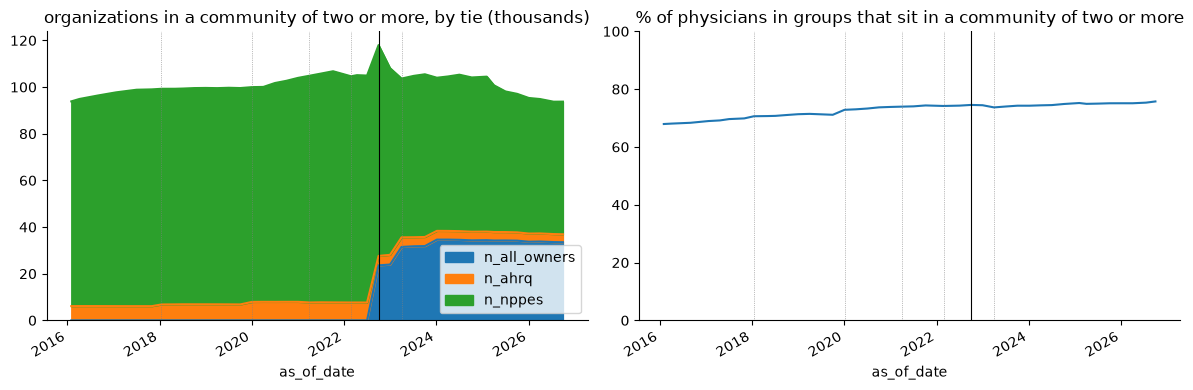

,ahrq_year,all_owners,n_communities_multi,n_organizations_multi,physicians_multi,physicians,n_all_owners,n_ahrq,n_nppes,n_staffing,churn,keyed_chain,keyed_nhc,keyed_irs
0,2016,False,32105,93836,433430.6,638031.2,0,6097,87766,219,NaN,9545,10091,10021
1,2016,False,32336,94863,438307.1,643787.0,0,6123,88767,230,0.0082,9483,10087,10002
2,2016,False,32781,96361,447528.3,654702.1,0,6119,90268,235,0.0109,9427,10130,10007
3,2016,False,33053,97693,457920.6,664081.5,0,6102,91615,242,0.0133,9534,10289,10329
4,2016,False,33323,98327,460525.1,665736.4,0,6092,92260,242,0.0080,9521,10300,10295
5,2016,False,33410,98829,464271.5,666674.7,0,6092,92762,240,0.0053,9476,10289,10284
6,2016,False,33405,98978,475271.5,680177.5,0,6084,92918,244,0.0075,9412,10249,10236
7,2018,False,33328,99236,483786.9,685018.0,0,6818,92438,263,0.0189,9492,10283,10307
8,2018,False,33254,99247,484541.9,685490.3,0,6851,92415,261,0.0069,9421,10101,10275
9,2018,False,33293,99338,485677.8,686482.1,0,6891,92467,228,0.0052,9395,10319,10281


In [15]:
s = stats.set_index(pd.to_datetime(stats.as_of_date))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(s[["n_all_owners", "n_ahrq", "n_nppes"]] / 1000).plot.area(ax=ax[0], title="organizations in a community of two or more, by tie (thousands)")
(100 * s.physicians_multi / s.physicians).plot(ax=ax[1], title="% of physicians in groups that sit in a community of two or more", ylim=(0, 100))
for a in ax:
    for d in s.index[s.ahrq_year.diff().fillna(0) != 0]:
        a.axvline(d, color="grey", lw=0.5, ls=":")
    a.axvline(pd.Timestamp(m["all_owners_from"]), color="black", lw=0.8)
plt.tight_layout(); plt.show()
s[["ahrq_year", "all_owners", "n_communities_multi", "n_organizations_multi", "physicians_multi", "physicians",
   "n_all_owners", "n_ahrq", "n_nppes", "n_staffing", "churn", "keyed_chain", "keyed_nhc", "keyed_irs"]].reset_index(drop=True)

Churn is the share of organizations whose community changes. It rises when an input changes: a new Compendium year, the start of All Owners firms, the Enrollments files adding home health agencies, or the end of the Nursing Home Compare owner lists (March 2022). Otherwise it stays low.

In [16]:
s["input change"] = np.where(s.ahrq_year.diff().fillna(0) != 0, "AHRQ year",
                     np.where(s.index == pd.Timestamp(m["all_owners_from"]), "All Owners start",
                     np.where(s.index == pd.Timestamp("2023-03-31"), "Enrollments add home health",
                     np.where(s.keyed_nhc.diff().fillna(0) < -1000, "Nursing Home Compare ends", "none"))))
s.iloc[1:].groupby("input change").churn.describe()[["count", "mean", "min", "max"]].round(4)

,count,mean,min,max
input change,,,,
AHRQ year,5.0,0.0177,0.0129,0.0231
All Owners start,1.0,0.0188,0.0188,0.0188
none,36.0,0.0073,0.0044,0.0133


The events table makes the id rule explicit. Each quarter records every flow of organizations between communities: `absorbed` when a community's id ends and its members go to another, `split` when a block leaves a surviving community for a new id, `move` between two surviving communities, `entry` and `exit` for organizations arriving in or leaving the graph.

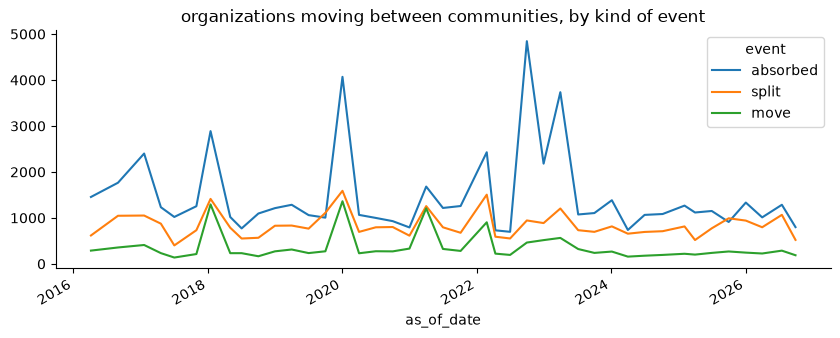

,as_of_date,event,n_organizations,from_name,to_name
0,2021-10-05,absorbed,329,"CLAYTON COUNTY DIALYSIS, LLC","TERRELL DIALYSIS CENTER, L.L.C."
1,2021-04-01,move,122,"AMERICAN ACCESS CARE OF TOWSON, LLC","CLAYTON COUNTY DIALYSIS, LLC"
2,2020-12-31,move,101,"AMERICAN ACCESS CARE OF TOWSON, LLC","CLAYTON COUNTY DIALYSIS, LLC"
3,2023-03-31,absorbed,100,"FORT PAYNE HOME CARE, LLC","LHC GROUP, INC"
4,2023-03-31,absorbed,52,"SOUTHEAST ALABAMA HOMECARE, LLC","LHC GROUP, INC"
5,2017-10-30,absorbed,50,"LHCG XXXVIII, LLC","LHCG XXXVII, LLC"
6,2020-01-02,absorbed,50,MANORCARE HEALTH SERVICES LLC,ProMedica
7,2026-01-02,absorbed,50,AMEDISYS INC,UNITEDHEALTH GROUP INCORPORATED
8,2023-03-31,split,47,"TEAM REHABILITATION BF2, LLC","TEAM REHABILITATION IL08, LLC"
9,2025-10-01,move,47,AMEDISYS INC,UNITEDHEALTH GROUP INCORPORATED


In [17]:
ev = con.execute("SELECT as_of_date, event, sum(n_organizations) AS organizations, count(*) AS flows FROM owner_community_event GROUP BY 1, 2 ORDER BY 1, 2").df()
pv = ev.pivot(index="as_of_date", columns="event", values="organizations").fillna(0).astype(int)
pv.index = pd.to_datetime(pv.index)
pv[["absorbed", "split", "move"]].iloc[1:].plot(title="organizations moving between communities, by kind of event", figsize=(10, 3.5))
plt.show()
big = con.execute("""WITH q AS (SELECT as_of_date, lag(as_of_date) OVER (ORDER BY as_of_date) AS prev FROM (SELECT DISTINCT as_of_date FROM owner_community_event)),
    named AS (SELECT community_id, name, effective_date, end_date FROM owner_community)
    SELECT e.as_of_date, e.event, e.n_organizations, f.name AS from_name, t.name AS to_name
    FROM owner_community_event e JOIN q USING (as_of_date)
    LEFT JOIN named f ON f.community_id = e.from_community_id AND f.effective_date <= q.prev AND (f.end_date IS NULL OR f.end_date > q.prev)
    LEFT JOIN named t ON t.community_id = e.to_community_id AND t.effective_date <= e.as_of_date AND (t.end_date IS NULL OR t.end_date > e.as_of_date)
    WHERE e.event IN ('absorbed', 'split', 'move') ORDER BY e.n_organizations DESC, e.as_of_date LIMIT 15""").df()
big

## 10. Flicker

An organization that leaves its community and comes back to it is the stability failure that matters for panels. The excursions that remain run a median of three months to a year and a half, depending on the quarter of return.

In [18]:
con.execute("""CREATE OR REPLACE TEMP TABLE runs AS
    WITH s AS (SELECT *, lag(community_id) OVER (PARTITION BY pac_id ORDER BY effective_date) AS prev FROM owner_community_member),
    g AS (SELECT *, sum((prev IS DISTINCT FROM community_id)::INT) OVER (PARTITION BY pac_id ORDER BY effective_date) AS run FROM s)
    SELECT pac_id, run, any_value(community_id) AS cid, min(effective_date) AS a FROM g GROUP BY 1, 2""")
con.execute("CREATE OR REPLACE TEMP TABLE runs2 AS SELECT *, lag(cid) OVER w AS c1, lag(cid, 2) OVER w AS c2 FROM runs WINDOW w AS (PARTITION BY pac_id ORDER BY run)")
con.execute("""SELECT count(DISTINCT pac_id) AS organizations, count(*) FILTER (c1 IS NOT NULL) AS moves,
               count(*) FILTER (c2 = cid) AS returns, count(DISTINCT pac_id) FILTER (c2 = cid) AS organizations_returning FROM runs2""").df()

,organizations,moves,returns,organizations_returning
0,513460,143811,7775,7070


## 11. The published headline, reproduced

The Compendium's own group practice files assign each physician's tax id to a system (AHRQ; Mathematica reports 56.9% of physicians in system-affiliated groups in 2018 and 61.9% in 2022 on that basis). Three measures on the same Compendium years, each over the physicians in groups the Compendium lists, weighted by `group_size.physicians` (each physician split across their groups): the Compendium's own system share; the share whose group's owner community holds a Compendium system; and the share whose community holds a hospital. The last column is the community-with-a-hospital share over every physician in the graph, not only the Compendium's groups, which is the measure the communities add.

In [19]:
rows = []
for y in sorted(con.execute("SELECT DISTINCT year FROM system_link WHERE node_type = 'organization' AND via = 'group practice file'").df().year):
    q = min(DATES, key=lambda d: abs((pd.Timestamp(d) - pd.Timestamp(f"{y}-07-01")).days))
    r = con.execute(f"""
        WITH mem AS (SELECT pac_id, community_id, basis FROM owner_community_member WHERE {ASOF(q)}),
        comm AS (SELECT community_id, n_hospitals FROM owner_community WHERE {ASOF(q)}),
        sysc AS (SELECT DISTINCT community_id FROM mem JOIN (SELECT node_id AS pac_id FROM system_link WHERE year = {y} AND node_type = 'organization' AND health_sys_id IS NOT NULL
                                                              UNION SELECT organization_pac_id FROM hospital_link h JOIN system_link s ON s.node_id = h.ccn AND s.year = {y} AND s.node_type = 'hospital' AND s.health_sys_id IS NOT NULL WHERE {ASOF(q, 'h.')}) x USING (pac_id)),
        ph AS (SELECT organization_pac_id AS pac_id, physicians FROM group_size WHERE as_of_date = (SELECT max(as_of_date) FROM group_size WHERE as_of_date <= DATE '{q}')),
        listed AS (SELECT node_id AS pac_id, max(health_sys_id IS NOT NULL)::INT AS in_sys FROM system_link WHERE year = {y} AND node_type = 'organization' GROUP BY 1)
        SELECT {y} AS year, '{q}' AS quarter,
               round(100 * sum(ph.physicians * l.in_sys) / sum(ph.physicians), 1) AS compendium_system_share,
               round(100 * sum(ph.physicians * (sc.community_id IS NOT NULL)::INT) / sum(ph.physicians), 1) AS community_with_system_share,
               round(100 * sum(ph.physicians * (c.n_hospitals > 0)::INT) / sum(ph.physicians), 1) AS community_with_hospital_share,
               (SELECT round(100 * sum(p2.physicians * (c2.n_hospitals > 0)::INT) / sum(p2.physicians), 1) FROM ph p2 JOIN mem m2 USING (pac_id) JOIN comm c2 USING (community_id)) AS all_physicians_community_with_hospital
        FROM listed l JOIN ph USING (pac_id) JOIN mem USING (pac_id) JOIN comm c USING (community_id) LEFT JOIN sysc sc USING (community_id)""").df()
    rows.append(r)
pd.concat(rows).reset_index(drop=True)

,year,quarter,compendium_system_share,community_with_system_share,community_with_hospital_share,all_physicians_community_with_hospital
0,2016,2016-08-30,54.3,55.8,55.3,45.2
1,2018,2018-07-03,58.2,59.5,58.8,47.8
2,2020,2020-07-01,60.8,62.3,59.9,51.8
3,2021,2021-07-01,62.3,63.7,61.1,52.5
4,2022,2022-07-01,62.7,64.3,62.0,53.1


## 12. The largest communities

On the last quarter, by physicians: the integrated systems, each named for its Compendium system, with the organizations tied in by firm, Compendium and soft keys.

In [20]:
b.close()
last = DATES[-1]
oc_last = con.execute(f"SELECT * EXCLUDE (effective_date, end_date) FROM owner_community WHERE {ASOF(last)}").df()
basis = con.execute(f"""SELECT community_id, count(*) FILTER (basis = 'all_owners') AS all_owners, count(*) FILTER (basis = 'ahrq') AS ahrq,
    count(*) FILTER (basis = 'nppes') AS soft FROM owner_community_member WHERE {ASOF(last)} GROUP BY 1""").df()
oc_last = oc_last.merge(basis, on="community_id")
print(last)
oc_last.sort_values("physicians", ascending=False).head(15).reset_index(drop=True)

2026-09-29


,community_id,name,n_organizations,n_hospitals,n_post_acute,physicians,all_owners,ahrq,soft
0,O1850367285,Kaiser Permanente,18,40,25,24658.4,10,8,0
1,O0648208504,Advocate Health,84,48,22,9512.6,53,31,0
2,O1355248584,University of California Health,60,3,0,8795.4,5,55,0
3,O1355361742,Mass General Brigham,45,13,2,7844.2,18,27,0
4,O0143138636,Trinity Health,202,83,51,7666.1,117,85,0
5,O0143117556,Ascension Health,194,79,66,7426.4,125,69,0
6,O0143271395,The University of Texas System,13,4,0,7110.0,5,8,0
7,O0042123598,CommonSpirit Health,169,118,59,7098.3,112,57,0
8,O0042124919,Mayo Clinic Health System,15,17,4,6945.9,14,1,0
9,O0941192116,Northwell Health,83,20,7,6639.2,30,53,0


By facilities: the post-acute chains, named for their All Owners firm, with few physicians.

In [21]:
oc_last.assign(facilities=oc_last.n_hospitals + oc_last.n_post_acute).sort_values("facilities", ascending=False).head(15).reset_index(drop=True)

,community_id,name,n_organizations,n_hospitals,n_post_acute,physicians,all_owners,ahrq,soft,facilities
0,O0143227496,THE ENSIGN GROUP INC,264,12,573,69.3,258,0,6,585
1,O0042220733,UNITEDHEALTH GROUP INCORPORATED,461,2,445,1.2,459,0,2,447
2,O7618252990,"PACS HOLDINGS, LLC",259,0,251,0.0,259,0,0,251
3,O3072556950,"KENTUCKY HOMECARE HOLDINGS, INC.",88,0,219,0.0,88,0,0,219
4,O0042395931,Universal Health Services,174,138,58,951.8,148,18,8,196
5,O0042128480,Sanford Health,60,42,150,2762.6,56,4,0,192
6,O0042121519,HCA Healthcare,387,151,31,4715.9,166,221,0,182
7,O0042123598,CommonSpirit Health,169,118,59,7098.3,112,57,0,177
8,O0143418459,GEN OPERATIONS II LLC,159,0,168,0.0,159,0,0,168
9,O0042301913,ENCOMPASS HEALTH CORPORATION,162,165,0,0.0,162,0,0,165


## 13. One community through time

The largest by physicians on the last quarter, through every quarter it exists.

## Limits and next steps

* The known owners that price the evidence are the Compendium's systems and All Owners firms. All Owners names each facility's reported owners, which for a nonprofit system is often a regional parent, so a firm understates the system; the system labels come first for that reason, and nursing homes, which the Compendium leaves outside any system, are priced against firms alone.
* IRS evidence reaches only organizations whose EIN an insurer's Transparency in Coverage file lists, as of the month the heads were fetched; organizations that left the networks before then have no EIN. A historical EIN roster (the Compendium's group practice files give tax-id names, not numbers) would extend it.
* The Compendium stops at 2023 and is carried forward; the Nursing Home Compare owner lists stop in March 2022, where All Owners begins.
* Firm names come from the All Owners files and are sometimes an owner's agent (an accounting or management firm) rather than the owner.
* The change-of-ownership files cover hospitals and nursing homes only; CMS publishes none for home health, hospice or clinics.

In [22]:
cid = oc_last.sort_values("physicians", ascending=False).community_id.iloc[0]
con.execute(f"SELECT effective_date, end_date, name, n_organizations, n_hospitals, n_post_acute, physicians FROM owner_community WHERE community_id = '{cid}' ORDER BY 1").df()

,effective_date,end_date,name,n_organizations,n_hospitals,n_post_acute,physicians
0,2016-02-01,2016-04-05,Kaiser Permanente,12,38,8,17307.6
1,2016-04-05,2016-08-30,Kaiser Permanente,12,38,8,17470.6
2,2016-08-30,2017-01-19,Kaiser Permanente,12,38,8,17711.1
3,2017-01-19,2017-04-20,Kaiser Permanente,12,38,8,18167.6
4,2017-04-20,2017-07-02,Kaiser Permanente,12,38,7,18323.0
5,2017-07-02,2017-10-30,Kaiser Permanente,12,38,7,18368.9
6,2017-10-30,2018-01-15,Kaiser Permanente,12,38,7,18556.5
7,2018-01-15,2018-05-02,Kaiser Permanente,11,39,8,20996.2
8,2018-05-02,2018-07-03,Kaiser Permanente,11,39,20,20997.6
9,2018-07-03,2018-10-02,Kaiser Permanente,11,39,20,20915.3
